# 02. Воспроизведение LR-4 и проверка вклада каждого признака

Выполненный небольшой эксперимент: исходная модель и четыре варианта
с исключением одного признака. Используем готовые значения признаков:
исходные PNG не нужны, извлечение 43 признаков не запускается.

Это проверка, какие из четырёх входов помогают текущей модели. Улучшения
здесь исследовательские: на этих данных уже выбирались методы, поэтому
победителя понадобится проверить на новой съёмке и новых пациентах.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

HERE = next(folder for parent in [Path.cwd(), *Path.cwd().parents]
            for folder in (parent, parent / 'fast_focus_4')
            if (folder / 'core.py').is_file() and (folder / 'workbench.py').is_file())
ROOT = HERE
if str(HERE.parent) not in sys.path:
    sys.path.insert(0, str(HERE.parent))
from fast_focus_4.workbench import (
    HERE, ART, PICTURES, BASIC, MODEL_IDS, load_data, baseline_table,
    load_model, predict_files, benchmark, run_ablations, photo_grid, verify_artifacts,
)
from fast_focus_4.core import decision_metrics, probability_metrics, calibration_bins
verify_artifacts()
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
table = load_data()
valid = table.loc[table.y >= 0].copy()
print(f'Корень: {ROOT}')
print(f'Всего {len(table)}; для обучения/метрик {len(valid)}; '
      f'ok={int(valid.y.sum())}, not_ok={int((valid.y == 0).sum())}; '
      f'пациентов={valid.patient_id.nunique()}')

Корень: C:\Users\chdd0\OneDrive\Рабочий стол\мфти\капилляроскоп\резкость\fast_focus_4
Всего 1000; для обучения/метрик 565; ok=62, not_ok=503; пациентов=93


## Зафиксированный протокол

565 согласованных кадров: 62 `ok`, 503 `not_ok`. Пять внешних частей по
пациентам, seed=20261102. В каждом внешнем обучении — три внутренние части
для sigmoid-калибровки и порогов. Внешние метки используются только для
расчёта метрик; StandardScaler обучается внутри train.

Все варианты используют один алгоритм LR с C=1 и balanced-весами.
Мы не выбираем порог на объединённых внешних прогнозах. Порог обычного
режима и строгий порог определяются отдельно внутри каждого обучения.
Воспроизведение исходной модели проверяется по всем вероятностям и порогам.

In [2]:
# Optional export is disabled; results remain embedded in this notebook.
EXPORT_RESULTS = False
OUT = HERE / 'local_outputs'
scores, predictions, folds = run_ablations(
    table, output_dir=OUT if EXPORT_RESULTS else None
)
display(scores[['experiment','n_features','auroc','auroc_delta_vs_baseline','ap',
                'precision_ok','recall_ok','tp','fp','fn','ece_ok_10','strict_accepted']].round(4))

baseline_4: AUROC=0.8800, AP=0.4679


without_laplacian_raw: AUROC=0.8703, AP=0.4348


without_laplacian_smooth: AUROC=0.8808, AP=0.4708


without_tenengrad_smooth: AUROC=0.8791, AP=0.4657

without_local_tenengrad_p75: AUROC=0.8814, AP=0.4738

,experiment,n_features,auroc,auroc_delta_vs_baseline,ap,precision_ok,recall_ok,tp,fp,fn,ece_ok_10,strict_accepted
0,baseline_4,4,0.8800,0.0000,0.4679,0.3333,0.8548,53,106,9,0.0406,0
1,without_laplacian_raw,3,0.8703,-0.0097,0.4348,0.3230,0.8387,52,109,10,0.0342,0
2,without_laplacian_smooth,3,0.8808,0.0009,0.4708,0.3376,0.8548,53,104,9,0.0385,0
3,without_tenengrad_smooth,3,0.8791,-0.0008,0.4657,0.3290,0.8226,51,104,11,0.0367,0
4,without_local_tenengrad_p75,3,0.8814,0.0014,0.4738,0.3478,0.9032,56,105,6,0.0353,0


`without_...` означает, что остальные три признака сохранены.
Падение качества после удаления показывает полезность признака для этой
модели; отсутствие падения может объясняться его избыточностью.
Это не причинное объяснение физики резкости.

## Сравнение на одинаковых внешних пациентах

Отдельные точки на графике — пять внешних частей. Их мало, размеры и
количество хороших кадров различаются. Разброс не является 95% интервалом.
Время обучения в CSV не является временем обработки одного изображения.

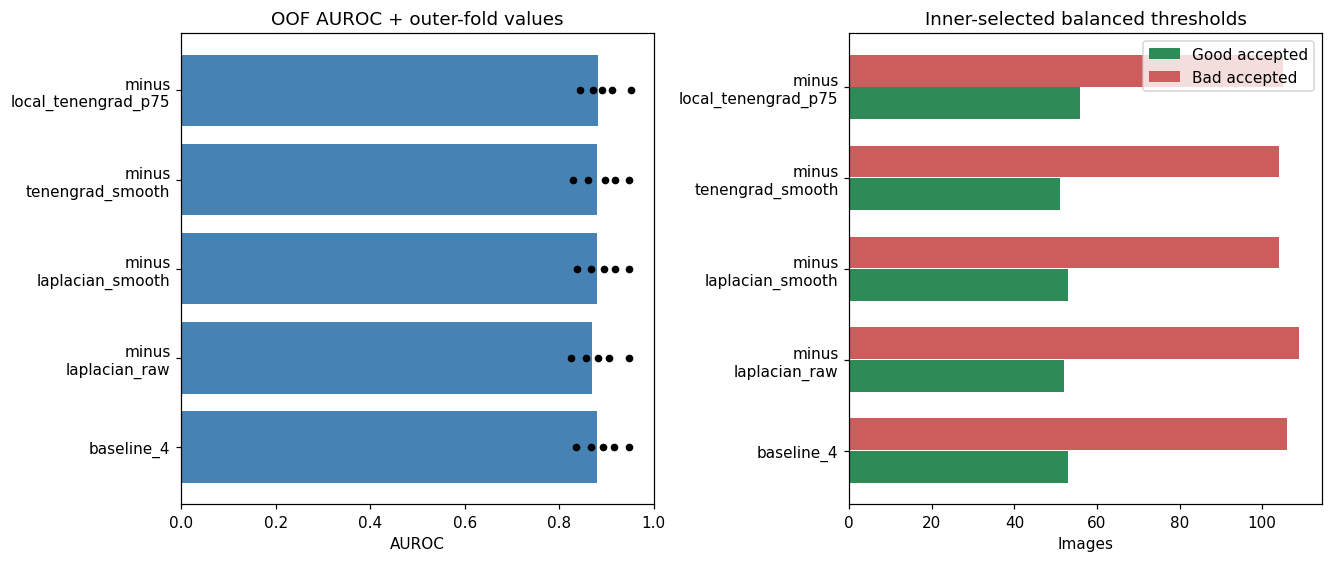

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
labels = [s.replace('without_', 'minus\n') for s in scores.experiment]
axes[0].barh(labels, scores.auroc, color='steelblue')
for i, name in enumerate(scores.experiment):
    v = folds.loc[folds.experiment == name, 'auroc']
    axes[0].scatter(v, np.full(len(v), i), c='black', s=16, zorder=3)
axes[0].set(xlim=(0,1), xlabel='AUROC', title='OOF AUROC + outer-fold values')
pos = np.arange(len(scores))
axes[1].barh(pos-.18, scores.tp, height=.35, label='Good accepted', color='seagreen')
axes[1].barh(pos+.18, scores.fp, height=.35, label='Bad accepted', color='indianred')
axes[1].set(yticks=pos, yticklabels=labels, xlabel='Images', title='Inner-selected balanced thresholds')
axes[1].legend()
plt.show()

In [4]:
# Парные разности AUROC: 1000 повторных выборок пациентов, фиксированные OOF-прогнозы.
# Это исследовательские интервалы: не учитывают переобучение и множественный выбор вариантов.
from sklearn.metrics import roc_auc_score
wide = predictions.pivot(index='file', columns='experiment', values='p_ok').loc[valid.file]
y = valid.y.to_numpy()
groups = valid.patient_id.to_numpy()
unique = np.unique(groups)
patient_rows = {g: np.flatnonzero(groups == g) for g in unique}
rng = np.random.default_rng(20261102)
deltas = {n: [] for n in scores.experiment if n != 'baseline_4'}
for _ in range(1000):
    ids = np.concatenate([patient_rows[g] for g in rng.choice(unique, len(unique), replace=True)])
    if len(np.unique(y[ids])) < 2:
        continue
    reference = roc_auc_score(y[ids], wide['baseline_4'].to_numpy()[ids])
    for name in deltas:
        deltas[name].append(roc_auc_score(y[ids], wide[name].to_numpy()[ids]) - reference)
intervals = pd.DataFrame([dict(experiment=n, delta_ci95_low=np.percentile(v,2.5),
                              delta_ci95_high=np.percentile(v,97.5)) for n,v in deltas.items()])
display(intervals.round(4))
if EXPORT_RESULTS:
    intervals.to_csv(OUT/'paired_auc_delta_ci.csv', index=False, encoding='utf-8-sig')

,experiment,delta_ci95_low,delta_ci95_high
0,without_laplacian_raw,-0.0135,-0.0057
1,without_laplacian_smooth,0.0001,0.0018
2,without_tenengrad_smooth,-0.0058,0.0043
3,without_local_tenengrad_p75,-0.0041,0.0071


## Вывод из выполненного сравнения

Исходные AUROC 0,87998 и решения 53 TP / 106 FP воспроизвелись.
Удаление исходного лапласиана снижает AUROC до 0,87026: несмотря на слабое
самостоятельное ранжирование, совместно с другими входами он полезен.
Удаление сглаженного лапласиана меняет AUROC до 0,88084 — прирост меньше 0,001.
Удаление локального p75 даёт AUROC 0,88142 и 56 TP / 105 FP;
интервал разности AUROC включает ноль. Явного решения проблемы отбора нет:
плохих допусков по-прежнему около сотни, строгий допуск отключён у всех вариантов.

Поэтому четыре признака сохраняем как исходный вариант. Небольшие изменения
не объявляем готовым улучшенным классификатором и не подменяем ими рабочие веса.

## Как продолжать

1. Пересмотреть уверенные ложные допуски и потери хороших из первого ноутбука.
2. Заранее выбрать цель: например, повысить precision при сохранении нужного recall
   и не увеличить p95 времени обработки. Числа требований нужно согласовать с задачей.
3. Менять по одному фактору: модель над четырьмя числами, обработка шума,
   нормировка контраста, затем масштаб изображения. Изменение вычисления признаков
   требует заново пересчитать признаки **и обучить модель**, старые веса не подходят.
4. Для подбора C, полиномиальных взаимодействий или параметров дерева выбирать их
   только внутри внешнего train с группировкой пациентов. Не выбирать по этому
   OOF лучшие параметры и не называть ту же оценку независимым тестом.
5. После фиксации метода проверить новую съёмку и новую разметку; отдельно измерить
   задержку на целевом компьютере. Спорные кадры не использовать как `not_ok`.

Уменьшение числа входов не гарантирует ускорения извлечения: текущая функция
`basic_only=True` всё равно считает все четыре. Здесь измерено влияние на качество.
Модели клиента и исходные артефакты этим ноутбуком не заменяются.